In [8]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:

import pandas as pd
import numpy as np
import pyarrow.parquet as pq

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

print("Libraries imported successfully!")


Libraries imported successfully!


In [10]:
PATH = '/content/drive/MyDrive/pods_AML_data/transactions_clean.parquet'

pf = pq.ParquetFile(PATH)

print("Number of rows:", pf.metadata.num_rows)
print("Number of row groups:", pf.metadata.num_row_groups)

print("\nDataset schema:")
print(pf.schema_arrow)


Number of rows: 5078345
Number of row groups: 5

Dataset schema:
txn_id: int32
ts: timestamp[ns]
date: timestamp[ns]
src_node: int32
dst_node: int32
src_bank: string
dst_bank: string
amount_paid: double
amount_received: double
cur_paid: string
cur_recv: string
payment_format: string
is_laundering: int8
split: string
is_self_loop: bool
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1854


In [11]:
df = pd.read_parquet(PATH)

print("Dataset shape:", df.shape)
print("Memory usage (MB):", round(df.memory_usage(deep=True).sum() / 1e6, 2))

print("\nFirst 5 transactions:")
display(df.head())

print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data type"))


Dataset shape: (5078345, 15)
Memory usage (MB): 1922.78

First 5 transactions:


,txn_id,ts,date,src_node,dst_node,src_bank,dst_bank,amount_paid,amount_received,cur_paid,cur_recv,payment_format,is_laundering,split,is_self_loop
0,2,2022-09-01,2022-09-01,2,2,03209,03209,14675.57,14675.57,US Dollar,US Dollar,Reinvestment,0,warmup,True
1,17,2022-09-01,2022-09-01,17,17,01420,01420,897.37,897.37,US Dollar,US Dollar,Reinvestment,0,warmup,True
2,158,2022-09-01,2022-09-01,131,131,010,010,99986.94,99986.94,US Dollar,US Dollar,Reinvestment,0,warmup,True
3,218,2022-09-01,2022-09-01,174,174,012,012,16.08,16.08,US Dollar,US Dollar,Reinvestment,0,warmup,True
4,281,2022-09-01,2022-09-01,219,219,001,001,10.30,10.30,US Dollar,US Dollar,Reinvestment,0,warmup,True



Column data types:


,Data type
txn_id,int32
ts,datetime64[ns]
date,datetime64[ns]
src_node,int32
dst_node,int32
src_bank,string[python]
dst_bank,string[python]
amount_paid,float64
amount_received,float64
cur_paid,string[python]


In [ ]:
print("Missing values:")
missing = df.isna().sum()
print(missing[missing > 0].to_dict() if missing.any() else "None")

print("\nAre transaction IDs unique?")
print(df['txn_id'].is_unique)

print("\nIs the dataset sorted by timestamp and transaction ID?")
key = df[['ts', 'txn_id']]
print(key.equals(key.sort_values(['ts', 'txn_id'])))

print("\nTransaction time range:")
print(df['ts'].min(), "to", df['ts'].max())

print("\nSplit summary:")
g = df.groupby('split', observed=True).agg(
    rows=('is_laundering', 'size'),
    positives=('is_laundering', 'sum'),
    t_min=('ts', 'min'),
    t_max=('ts', 'max')
)

g['prevalence_%'] = (
    100 * g['positives'] / g['rows']
).round(4)

display(g)


Missing values:
None

Are transaction IDs unique?
True

Is the dataset sorted by timestamp and transaction ID?
True

Transaction time range:
2022-09-01 00:00:00 to 2022-09-18 16:18:00

Split summary:


,rows,positives,t_min,t_max,prevalence_%
split,,,,,
tail,1108,655,2022-09-11 00:05:00,2022-09-18 16:18:00,59.1155
test,862792,956,2022-09-09 00:00:00,2022-09-10 23:59:00,0.1108
train,2134000,2208,2022-09-02 00:00:00,2022-09-06 23:59:00,0.1035
val,965524,1036,2022-09-07 00:00:00,2022-09-08 23:59:00,0.1073
warmup,1114921,322,2022-09-01 00:00:00,2022-09-01 23:59:00,0.0289


In [ ]:
print("Memory before conversion (MB):",
      round(df.memory_usage(deep=True).sum() / 1e6, 2))

categorical_columns = [
    'src_bank',
    'dst_bank',
    'cur_paid',
    'cur_recv',
    'payment_format',
    'split'
]

for col in categorical_columns:
    df[col] = df[col].astype('category')

print("Memory after conversion (MB):",
      round(df.memory_usage(deep=True).sum() / 1e6, 2))


Memory before conversion (MB): 1922.78
Memory after conversion (MB): 278.41


In [ ]:
print("Share where ts differs from date:",
      round((df['ts'] != df['date']).mean(), 4))

print("\nUnique hours present:")
print(sorted(df['ts'].dt.hour.unique()))

print("\nSample timestamps:")
display(df[['ts', 'date']].head(10))


Share where ts differs from date: 0.9964

Unique hours present:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]

Sample timestamps:


,ts,date
0,2022-09-01,2022-09-01
1,2022-09-01,2022-09-01
2,2022-09-01,2022-09-01
3,2022-09-01,2022-09-01
4,2022-09-01,2022-09-01
5,2022-09-01,2022-09-01
6,2022-09-01,2022-09-01
7,2022-09-01,2022-09-01
8,2022-09-01,2022-09-01
9,2022-09-01,2022-09-01


In [ ]:
# Check whether the stored flag matches the node IDs
matches = (df['src_node'] == df['dst_node']) == df['is_self_loop']

print("Self-loop flag matches source/destination IDs:", matches.all())
print("Number of inconsistent rows:", int((~matches).sum()))

print("\nSelf-loop transactions:")
print("Count:", int(df['is_self_loop'].sum()))
print("Percentage:", round(100 * df['is_self_loop'].mean(), 4), "%")


Self-loop flag matches source/destination IDs: True
Number of inconsistent rows: 0

Self-loop transactions:
Count: 591212
Percentage: 11.6418 %


In [ ]:
print("Transactions with amount_paid <= 0:",
      int((df['amount_paid'] <= 0).sum()))

print("Transactions with amount_received <= 0:",
      int((df['amount_received'] <= 0).sum()))

same_currency = df['cur_paid'] == df['cur_recv']

print("\nSame-currency transactions:",
      int(same_currency.sum()))

print("Cross-currency transactions:",
      int((~same_currency).sum()))

print("Cross-currency percentage:",
      round(100 * (~same_currency).mean(), 4), "%")

same_currency_amounts_differ = (
    same_currency &
    (df['amount_paid'] != df['amount_received'])
)

print("\nSame currency but different paid/received amounts:",
      int(same_currency_amounts_differ.sum()))

print("Percentage among same-currency transactions:",
      round(
          100 * same_currency_amounts_differ.sum() /
          max(int(same_currency.sum()), 1),
          4
      ), "%")


Transactions with amount_paid <= 0: 0
Transactions with amount_received <= 0: 0

Same-currency transactions: 5006175
Cross-currency transactions: 72170
Cross-currency percentage: 1.4211 %

Same currency but different paid/received amounts: 0
Percentage among same-currency transactions: 0.0 %


In [ ]:

format_loop_summary = (
    df.groupby('payment_format', observed=True)
      .agg(
          transactions=('is_self_loop', 'size'),
          self_loops=('is_self_loop', 'sum'),
          self_loop_rate=('is_self_loop', 'mean')
      )
      .sort_values('transactions', ascending=False)
)

format_loop_summary['self_loop_rate_%'] = (
    100 * format_loop_summary['self_loop_rate']
).round(3)

display(
    format_loop_summary[
        ['transactions', 'self_loops', 'self_loop_rate_%']
    ]
)

print(
    "\nOverall Reinvestment transactions:",
    int((df['payment_format'] == 'Reinvestment').sum())
)

print(
    "Reinvestment transactions that are self-loops:",
    int(
        (
            (df['payment_format'] == 'Reinvestment') &
            df['is_self_loop']
        ).sum()
    )
)


,transactions,self_loops,self_loop_rate_%
payment_format,,,
Cheque,1864331,6066,0.325
Credit Card,1323324,4176,0.316
ACH,600797,71347,11.875
Cash,490891,1455,0.296
Reinvestment,481056,481056,100.000
Wire,171855,795,0.463
Bitcoin,146091,26317,18.014



Overall Reinvestment transactions: 481056
Reinvestment transactions that are self-loops: 481056


In [ ]:
# Check whether each node belongs to only one bank
pairs = pd.concat([
    df[['src_node', 'src_bank']].set_axis(['node', 'bank'], axis=1),
    df[['dst_node', 'dst_bank']].set_axis(['node', 'bank'], axis=1)
]).drop_duplicates()

# Count the number of different banks associated with each node
banks_per_node = pairs.groupby('node', observed=True)['bank'].nunique()

# Display the results
print("Unique nodes:", len(banks_per_node))
print("Nodes with multiple banks:", (banks_per_node > 1).sum())

Unique nodes: 515088
Nodes with multiple banks: 0


In [ ]:
# Check for duplicate transaction details, ignoring the transaction ID
cols = [c for c in df.columns if c != 'txn_id']

print("Duplicate rows:", df.duplicated(subset=cols).sum())

Duplicate rows: 9


In [ ]:
# Check the chronological boundaries of each split
order = ['warmup', 'train', 'val', 'test', 'tail']
b = df.groupby('split', observed=True)['ts'].agg(['min', 'max']).loc[order]

display(b)

# Check that each split starts after the previous split ends
print("Splits follow chronological order:",
      all(b['max'].iloc[i] <= b['min'].iloc[i+1]
          for i in range(len(order)-1)))

,min,max
split,,
warmup,2022-09-01 00:00:00,2022-09-01 23:59:00
train,2022-09-02 00:00:00,2022-09-06 23:59:00
val,2022-09-07 00:00:00,2022-09-08 23:59:00
test,2022-09-09 00:00:00,2022-09-10 23:59:00
tail,2022-09-11 00:05:00,2022-09-18 16:18:00


Splits follow chronological order: True


In [ ]:
# Summarize normal and laundering transactions in each split
order = ['warmup', 'train', 'val', 'test', 'tail']

s = df.groupby('split', observed=True)['is_laundering'].agg(
    rows='size', pos='sum'
).loc[order]

# Calculate negative counts, positive rate, and imbalance ratio
s['neg'] = s['rows'] - s['pos']
s['prev_%'] = (100 * s['pos'] / s['rows']).round(4)
s['neg_per_pos'] = (s['neg'] / s['pos']).round(0)
s['sqrt_spw'] = np.sqrt(s['neg_per_pos']).round(1)

display(s)


,rows,pos,neg,prev_%,neg_per_pos,sqrt_spw
split,,,,,,
warmup,1114921,322,1114599,0.0289,3461.0,58.8
train,2134000,2208,2131792,0.1035,965.0,31.1
val,965524,1036,964488,0.1073,931.0,30.5
test,862792,956,861836,0.1108,902.0,30.0
tail,1108,655,453,59.1155,1.0,1.0


In [ ]:
# Summarize daily transaction volume and positive counts
daily = df.groupby('date', observed=True).agg(
    rows=('is_laundering', 'size'),
    pos=('is_laundering', 'sum')
).reset_index()

daily['rate_%'] = (100 * daily['pos'] / daily['rows']).round(4)

display(daily)


,date,rows,pos,rate_%
0,2022-09-01,1114921,322,0.0289
1,2022-09-02,754449,408,0.0541
2,2022-09-03,207382,391,0.1885
3,2022-09-04,207430,407,0.1962
4,2022-09-05,482650,471,0.0976
5,2022-09-06,482089,531,0.1101
6,2022-09-07,482751,497,0.1030
7,2022-09-08,482773,539,0.1116
8,2022-09-09,654467,514,0.0785
9,2022-09-10,208325,442,0.2122


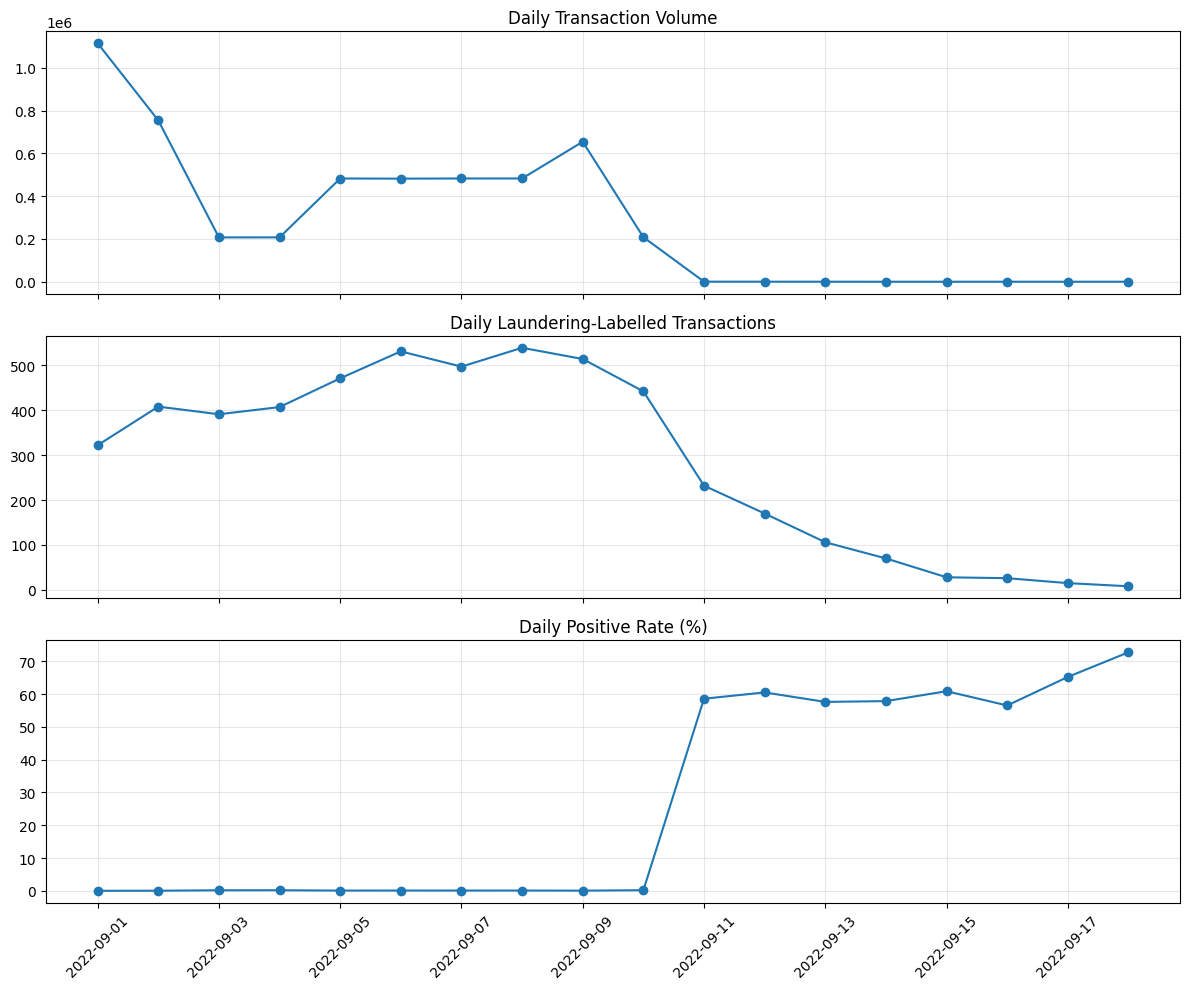

In [ ]:
# Plot daily transaction volume, positive counts, and positive rate
import matplotlib.pyplot as plt

daily['split'] = daily['date'].dt.day.map(
    lambda d: 'warmup' if d == 1 else
    'train' if 2 <= d <= 6 else
    'val' if 7 <= d <= 8 else
    'test' if 9 <= d <= 10 else 'tail'
)

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Transactions per day
axes[0].plot(daily['date'], daily['rows'], marker='o')
axes[0].set_title('Daily Transaction Volume')

# Positive transactions per day
axes[1].plot(daily['date'], daily['pos'], marker='o')
axes[1].set_title('Daily Laundering-Labelled Transactions')

# Positive rate per day
axes[2].plot(daily['date'], daily['rate_%'], marker='o')
axes[2].set_title('Daily Positive Rate (%)')

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# Compare laundering labels for self-loop and non-self-loop transactions
loop_check = df.groupby('is_self_loop', observed=True)['is_laundering'].agg(
    transactions='size',
    positives='sum',
    positive_rate='mean'
).reset_index()

# Convert positive rate to percentage
loop_check['positive_rate_%'] = (loop_check['positive_rate'] * 100).round(4)

display(loop_check.drop(columns='positive_rate'))


,is_self_loop,transactions,positives,positive_rate_%
0,False,4487133,5166,0.1151
1,True,591212,11,0.0019


In [ ]:
# Compare laundering rates across payment formats
payment_check = df.groupby('payment_format', observed=True)['is_laundering'].agg(
    transactions='size',
    positives='sum',
    positive_rate='mean'
).reset_index()

# Show the positive rate as a percentage
payment_check['positive_rate_%'] = (
    payment_check['positive_rate'] * 100
).round(4)

display(
    payment_check.drop(columns='positive_rate')
    .sort_values('positive_rate_%', ascending=False)
)


,payment_format,transactions,positives,positive_rate_%
0,ACH,600797,4483,0.7462
1,Bitcoin,146091,56,0.0383
2,Cash,490891,108,0.0220
3,Cheque,1864331,324,0.0174
4,Credit Card,1323324,206,0.0156
5,Reinvestment,481056,0,0.0000
6,Wire,171855,0,0.0000


In [ ]:
# Analyze payment formats using training data only
train_payment = df[df['split'] == 'train']

payment_train_check = train_payment.groupby(
    'payment_format', observed=True
)['is_laundering'].agg(
    transactions='size',
    positives='sum',
    positive_rate='mean'
).reset_index()

# Convert the positive rate to a percentage
payment_train_check['positive_rate_%'] = (
    payment_train_check['positive_rate'] * 100
).round(4)

display(
    payment_train_check.drop(columns='positive_rate')
    .sort_values('positive_rate_%', ascending=False)
)


,payment_format,transactions,positives,positive_rate_%
0,ACH,277040,1888,0.6815
1,Bitcoin,61670,32,0.0519
2,Cash,228861,45,0.0197
3,Cheque,863499,146,0.0169
4,Credit Card,623440,97,0.0156
5,Wire,79490,0,0.0000


In [ ]:
# Compare transaction amounts for normal and laundering-labelled training rows
train = df[df['split'] == 'train']

amount_check = train.groupby('is_laundering', observed=True).agg(
    transactions=('amount_paid', 'size'),
    median_amount=('amount_paid', 'median'),
    p90_amount=('amount_paid', lambda x: x.quantile(0.90)),
    p99_amount=('amount_paid', lambda x: x.quantile(0.99)),
    max_amount=('amount_paid', 'max')
).reset_index()

display(amount_check.round(2))


,is_laundering,transactions,median_amount,p90_amount,p99_amount,max_amount
0,0,2131792,1372.30,107845.48,10966224.40,1.046302e+12
1,1,2208,7226.94,136041.22,27496434.62,2.150069e+10


In [ ]:
# Check whether timestamps contain different hours
h = df['ts'].dt.hour

print("distinct hours:", h.nunique(), "| ts == date share:", round((df.ts == df.date).mean(), 4))

HAS_HOUR = h.nunique() > 1
print("HAS_HOUR =", HAS_HOUR)


distinct hours: 24 | ts == date share: 0.0036
HAS_HOUR = True


ts,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
rows,158606.000,86176.000,85862.000,86266.000,85955.000,86415.000,86303.000,85888.000,85360.000,85798.000,86037.000,85883.000,85826.000,85682.000,85622.000,86612.000,86045.000,85483.000,85262.000,85873.000,86387.000,85577.00,85221.000,85861.000
pos,81.000,80.000,72.000,63.000,67.000,74.000,93.000,88.000,113.000,87.000,88.000,122.000,130.000,127.000,119.000,109.000,144.000,105.000,105.000,99.000,54.000,60.00,58.000,70.000
rate_%,0.051,0.093,0.084,0.073,0.078,0.086,0.108,0.102,0.132,0.101,0.102,0.142,0.151,0.148,0.139,0.126,0.167,0.123,0.123,0.115,0.063,0.07,0.068,0.082


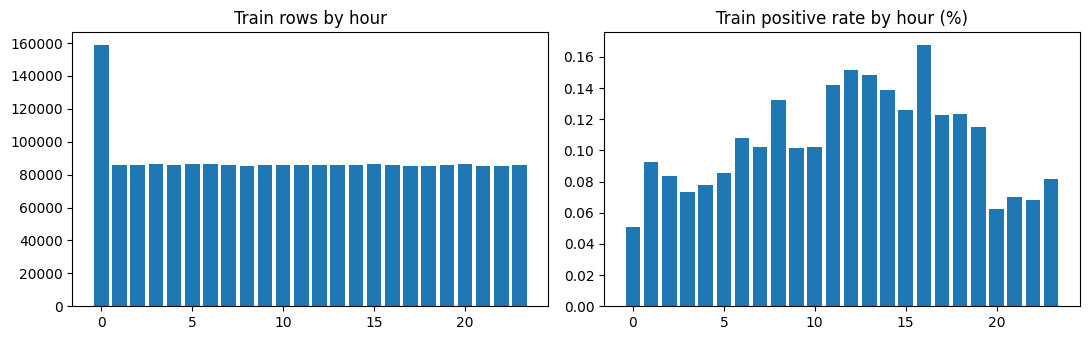

In [ ]:
# Check hourly transaction counts and positive rates using training data only
if HAS_HOUR:
    tr = df[df.split == 'train']
    hp = tr.groupby(tr.ts.dt.hour)['is_laundering'].agg(rows='size', pos='sum')
    hp['rate_%'] = 100 * hp.pos / hp.rows
    display(hp.round(3).T)

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].bar(hp.index, hp.rows)
    ax[0].set_title('Train rows by hour')
    ax[1].bar(hp.index, hp['rate_%'])
    ax[1].set_title('Train positive rate by hour (%)')
    plt.tight_layout()
    plt.show()


log10(amount_paid) quantiles by split:


,0.05,0.25,0.50,0.75,0.95
split,,,,,
train,0.96,2.31,3.14,4.03,5.69
val,0.92,2.29,3.10,3.98,5.63
test,1.00,2.30,3.09,3.99,5.64
tail,2.95,3.74,4.11,4.58,6.15


payment_format,ACH,Bitcoin,Cash,Cheque,Credit Card,Wire
split,,,,,,
train,12.98,2.89,10.72,40.46,29.21,3.72
val,12.11,2.97,10.70,41.13,29.29,3.80
test,13.82,2.82,10.63,40.22,29.00,3.51
tail,100.00,0.00,0.00,0.00,0.00,0.00


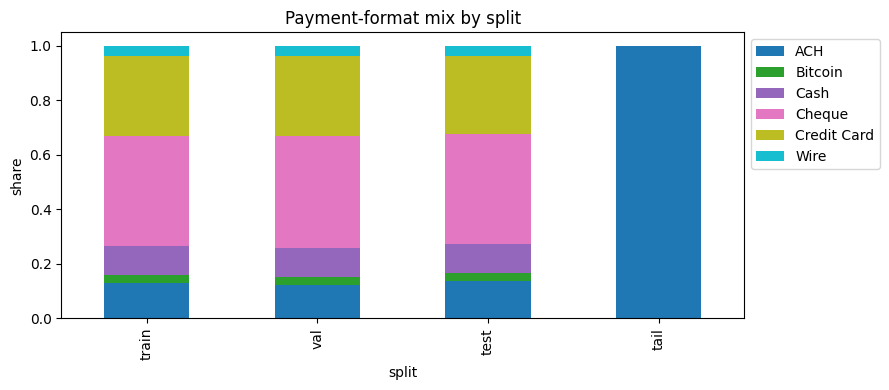

,self_loop_pct,cross_cur_pct
split,,
train,2.11,1.57
val,2.15,1.60
test,2.04,1.53
tail,35.47,35.29


In [ ]:
# Compare amount distributions, payment formats, self-loops, and currencies
order = ['warmup', 'train', 'val', 'test', 'tail']
d = df[df.split != 'warmup'].copy()

d['log_amt'] = np.log10(d.amount_paid.clip(lower=0.01))
q = d.groupby('split', observed=True)['log_amt'].quantile(
    [0.05, 0.25, 0.5, 0.75, 0.95]
).unstack()

print("log10(amount_paid) quantiles by split:")
display(q.loc[['train', 'val', 'test', 'tail']].round(2))

mix = pd.crosstab(d.split, d.payment_format, normalize='index').loc[
    ['train', 'val', 'test', 'tail']
]
display((100 * mix).round(2))

mix.plot(kind='bar', stacked=True, figsize=(9, 4), colormap='tab10')
plt.title('Payment-format mix by split')
plt.ylabel('share')
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

extra = d.groupby('split', observed=True).agg(
    self_loop_pct=('is_self_loop', lambda x: 100 * x.mean())
)
extra['cross_cur_pct'] = (
    100 * (d.cur_paid != d.cur_recv).groupby(d.split, observed=True).mean()
)

display(extra.loc[['train', 'val', 'test', 'tail']].round(2))


In [ ]:
# Define accounts seen during warmup or training
known = pd.unique(np.concatenate([
    df.loc[df.split.isin(['warmup', 'train']), 'src_node'].values,
    df.loc[df.split.isin(['warmup', 'train']), 'dst_node'].values
]))

# Measure unseen sender and receiver accounts in later splits
rows = []
for sp in ['val', 'test', 'tail']:
    x = df[df.split == sp]
    src_seen = np.isin(x.src_node.values, known)
    dst_seen = np.isin(x.dst_node.values, known)

    rows.append({
        'split': sp,
        'src_unseen_%': round(100 * (~src_seen).mean(), 2),
        'dst_unseen_%': round(100 * (~dst_seen).mean(), 2),
        'both_seen_%': round(100 * (src_seen & dst_seen).mean(), 2)
    })

display(pd.DataFrame(rows).set_index('split'))


,src_unseen_%,dst_unseen_%,both_seen_%
split,,,
val,0.10,0.09,99.81
test,0.12,0.10,99.78
tail,2.71,2.08,96.30


In [ ]:
# Use training rows only
tr = df[df.split == 'train'].copy()

tr['log_amt'] = np.log10(tr.amount_paid.clip(lower=0.01))
tr['same_bank'] = tr.src_bank.astype(str) == tr.dst_bank.astype(str)
tr['cross_cur'] = tr.cur_paid.astype(str) != tr.cur_recv.astype(str)
tr['round_100'] = tr.amount_paid % 100 == 0
tr['round_1000'] = tr.amount_paid % 1000 == 0

base = tr.is_laundering.mean()
print("train rows:", len(tr), "| positives:", int(tr.is_laundering.sum()),
      "| base rate %:", round(100 * base, 4))


train rows: 2134000 | positives: 2208 | base rate %: 0.1035


In [ ]:
# Compare positive rates for each flag
rows = []

for f in ['is_self_loop', 'same_bank', 'cross_cur', 'round_100', 'round_1000']:
    for v in [False, True]:
        m = tr[f] == v
        rate = tr.loc[m, 'is_laundering'].mean()
        rows.append({
            'flag': f,
            'value': v,
            'rows': int(m.sum()),
            'pos': int(tr.loc[m, 'is_laundering'].sum()),
            'rate_%': round(100 * rate, 4),
            'lift': round(rate / base, 2)
        })

display(pd.DataFrame(rows))


,flag,value,rows,pos,rate_%,lift
0,is_self_loop,False,2089024,2203,0.1055,1.02
1,is_self_loop,True,44976,5,0.0111,0.11
2,same_bank,False,2042406,2168,0.1061,1.03
3,same_bank,True,91594,40,0.0437,0.42
4,cross_cur,False,2100475,2208,0.1051,1.02
5,cross_cur,True,33525,0,0.0000,0.00
6,round_100,False,2133773,2207,0.1034,1.00
7,round_100,True,227,1,0.4405,4.26
8,round_1000,False,2133976,2208,0.1035,1.00
9,round_1000,True,24,0,0.0000,0.00


In [ ]:
# Compare payment formats and currencies using training data only
def cat_table(col, min_rows=500):
    t = tr.groupby(col, observed=True)['is_laundering'].agg(
        rows='size', pos='sum'
    )
    t['rate_%'] = 100 * t.pos / t.rows
    t['lift'] = t['rate_%'] / (100 * base)
    t['share_of_pos_%'] = 100 * t.pos / t.pos.sum()
    return t[t.rows >= min_rows].sort_values(
        'rate_%', ascending=False
    ).round(3)

for c in ['payment_format', 'cur_paid']:
    print(f"\n{c}:")
    display(cat_table(c))



payment_format:


,rows,pos,rate_%,lift,share_of_pos_%
payment_format,,,,,
ACH,277040,1888,0.681,6.587,85.507
Bitcoin,61670,32,0.052,0.502,1.449
Cash,228861,45,0.020,0.190,2.038
Cheque,863499,146,0.017,0.163,6.612
Credit Card,623440,97,0.016,0.150,4.393
Wire,79490,0,0.000,0.000,0.000



cur_paid:


,rows,pos,rate_%,lift,share_of_pos_%
cur_paid,,,,,
Saudi Riyal,37585,143,0.380,3.677,6.476
Canadian Dollar,59018,67,0.114,1.097,3.034
Euro,490794,552,0.112,1.087,25.000
Rupee,79602,88,0.111,1.068,3.986
US Dollar,796101,823,0.103,0.999,37.274
Ruble,65189,66,0.101,0.979,2.989
Brazil Real,29642,29,0.098,0.946,1.313
Yuan,89884,86,0.096,0.925,3.895
UK Pound,76607,67,0.087,0.845,3.034


log10(amount_paid) quantiles by class:


,0.05,0.25,0.50,0.75,0.95
is_laundering,,,,,
0,0.96,2.31,3.14,4.03,5.69
1,2.26,3.38,3.86,4.27,5.89


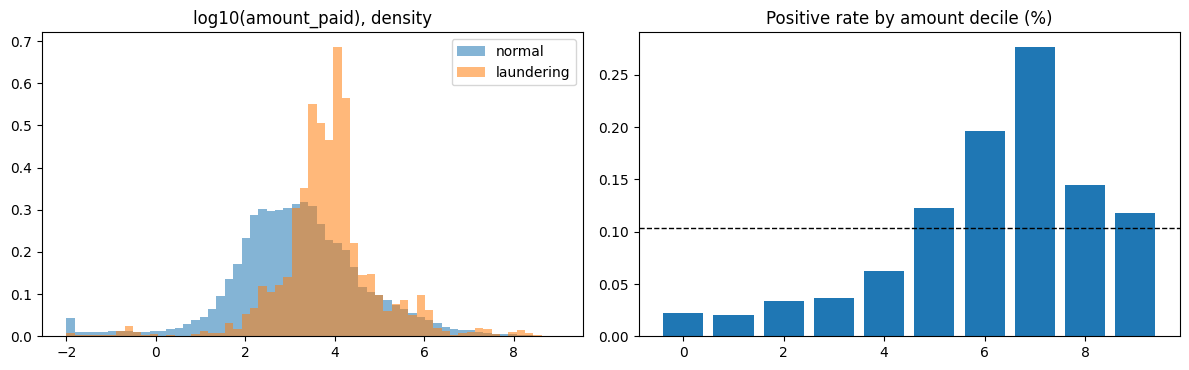

In [ ]:
# Compare amount distributions for normal and positive transactions
print("log10(amount_paid) quantiles by class:")
display(
    tr.groupby('is_laundering')['log_amt']
    .quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    .unstack().round(2)
)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(-2, 9, 60)

ax[0].hist(tr.loc[tr.is_laundering == 0, 'log_amt'],
            bins=bins, density=True, alpha=0.55, label='normal')
ax[0].hist(tr.loc[tr.is_laundering == 1, 'log_amt'],
            bins=bins, density=True, alpha=0.55, label='laundering')
ax[0].set_title('log10(amount_paid), density')
ax[0].legend()

# Compare positive rates across amount deciles
tr['amt_decile'] = pd.qcut(
    tr.amount_paid, 10, labels=False, duplicates='drop'
)
dr = 100 * tr.groupby('amt_decile')['is_laundering'].mean()

ax[1].bar(dr.index, dr.values)
ax[1].axhline(100 * base, ls='--', c='k', lw=1)
ax[1].set_title('Positive rate by amount decile (%)')

plt.tight_layout()
plt.show()


In [ ]:
# Check laundering labels for each payment-format and self-loop combination
ct = pd.crosstab(
    [tr.payment_format, tr.is_self_loop],
    tr.is_laundering
)

ct['rate_pct'] = (
    100 * ct[1] / (ct[0] + ct[1])
).round(4)

display(ct)


is_laundering                     0     1  rate_pct
payment_format is_self_loop                        
ACH            False         242002  1883    0.7721
               True           33150     5    0.0151
Bitcoin        False          55643    32    0.0575
               True            5995     0    0.0000
Cash           False         228153    45    0.0197
               True             663     0    0.0000
Cheque         False         860519   146    0.0170
               True            2834     0    0.0000
Credit Card    False         621386    97    0.0156
               True            1957     0    0.0000
Wire           False          79118     0    0.0000
               True             372     0    0.0000

In [ ]:
# Use training data only and create candidate features
from sklearn.metrics import average_precision_score
from sklearn.tree import DecisionTreeClassifier

tr = df[df.split == 'train'].copy()
tr['log_amt'] = np.log10(tr.amount_paid.clip(lower=0.01))
tr['same_bank'] = (tr.src_bank.astype(str) == tr.dst_bank.astype(str)).astype(int)
tr['cross_cur'] = (tr.cur_paid.astype(str) != tr.cur_recv.astype(str)).astype(int)
tr['round_100'] = (tr.amount_paid % 100 == 0).astype(int)
tr['hour'] = tr.ts.dt.hour
tr['self_loop'] = tr.is_self_loop.astype(int)
tr['day_pos'] = tr.groupby('date').cumcount()
tr['txn_id_rank'] = tr.groupby('date')['txn_id'].rank(pct=True)

# Fit on earlier training days and evaluate on later training days
days = np.sort(tr.date.unique())
cut = days[int(len(days) * 0.6)]
fit, ev = tr[tr.date < cut], tr[tr.date >= cut]

print("fit days:", (days < cut).sum(), "| eval days:", (days >= cut).sum())
print("fit rows:", len(fit), "pos:", int(fit.is_laundering.sum()),
      "| eval rows:", len(ev), "pos:", int(ev.is_laundering.sum()))

prev = ev.is_laundering.mean()
print("eval prevalence %:", round(100 * prev, 4))


fit days: 3 | eval days: 2
fit rows: 1169261 pos: 1206 | eval rows: 964739 pos: 1002
eval prevalence %: 0.1039


,column,type,pr_auc,lift_vs_prev
7,txn_id_rank,numeric/flag,0.22127,213.0
14,dst_node,categorical,0.07376,71.0
13,src_node,categorical,0.04393,42.3
8,payment_format,categorical,0.00661,6.4
11,src_bank,categorical,0.00461,4.4
12,dst_bank,categorical,0.00282,2.7
0,log_amt,numeric/flag,0.00223,2.1
9,cur_paid,categorical,0.00137,1.3
10,cur_recv,categorical,0.00136,1.3
4,hour,numeric/flag,0.00128,1.2


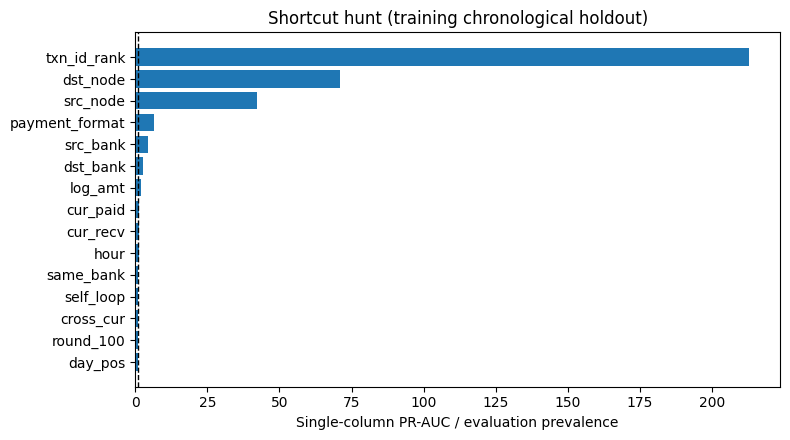

In [ ]:
# Score numeric columns and flags with a small decision tree
def num_score(col, depth=4):
    model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=500)
    model.fit(fit[[col]].values, fit.is_laundering.values)
    pred = model.predict_proba(ev[[col]].values)[:, 1]
    return average_precision_score(ev.is_laundering, pred)

# Score categorical columns using smoothed positive rates from fit data
def cat_score(col, smooth=50):
    gm = fit.is_laundering.mean()
    g = fit.groupby(col, observed=True)['is_laundering'].agg(['sum', 'count'])
    enc = (g['sum'] + smooth * gm) / (g['count'] + smooth)
    scores = ev[col].map(enc).astype(float).fillna(gm)
    return average_precision_score(ev.is_laundering, scores)

res = []
for c in ['log_amt', 'same_bank', 'cross_cur', 'round_100',
          'hour', 'self_loop', 'day_pos', 'txn_id_rank']:
    res.append((c, 'numeric/flag', num_score(c)))

for c in ['payment_format', 'cur_paid', 'cur_recv',
          'src_bank', 'dst_bank', 'src_node', 'dst_node']:
    res.append((c, 'categorical', cat_score(c)))

out = pd.DataFrame(res, columns=['column', 'type', 'pr_auc'])
out = out.sort_values('pr_auc', ascending=False)
out['lift_vs_prev'] = (out.pr_auc / prev).round(1)

display(out.round(5))

# Compare each column's score with the evaluation prevalence
plt.figure(figsize=(8, 4.5))
plt.barh(out.column[::-1], out.lift_vs_prev[::-1])
plt.axvline(1, color='black', linestyle='--', linewidth=1)
plt.xlabel('Single-column PR-AUC / evaluation prevalence')
plt.title('Shortcut hunt (training chronological holdout)')
plt.tight_layout()
plt.show()


In [ ]:
# Check whether transaction position within a day relates to the label
tr['pos_dec'] = pd.qcut(
    tr.txn_id_rank, 10, labels=False, duplicates='drop'
)

print("Positive rate % by within-day ID-rank decile:")
print(
    (100 * tr.groupby('pos_dec')['is_laundering'].mean())
    .round(4).to_string()
)

# Check whether a few accounts account for many positive transactions
pos = tr[tr.is_laundering == 1]

for side in ['src_node', 'dst_node']:
    vc = pos[side].value_counts()
    top_n = max(1, len(vc) // 100)

    print(
        f"{side}: {len(vc)} distinct accounts hold {len(pos)} positives | "
        f"top 1% hold {100 * vc.head(top_n).sum() / len(pos):.1f}% of positives"
    )


Positive rate % by within-day ID-rank decile:
pos_dec
0    0.4700
1    0.0825
2    0.0586
3    0.0722
4    0.0553
5    0.0651
6    0.0600
7    0.0623
8    0.0492
9    0.0595
src_node: 1565 distinct accounts hold 2208 positives | top 1% hold 15.9% of positives
dst_node: 1779 distinct accounts hold 2208 positives | top 1% hold 10.1% of positives


In [ ]:
t = df[df.split == 'train'].copy()
t['rk'] = t.groupby('date')['txn_id'].rank(pct=True)
t['tod'] = t.ts.dt.hour + t.ts.dt.minute/60
print("spearman(rank, time of day):", round(t[['rk','tod']].corr(method='spearman').iloc[0,1], 3))
print(t.groupby(pd.cut(t.rk, [0,.01,.02,.05,.1,.2,1]), observed=True)['is_laundering'].agg(['size','sum','mean']))
print(t[t.rk <= .1].groupby('date')['is_laundering'].mean().round(5))

spearman(rank, time of day): 0.997
                 size   sum      mean
rk                                   
(0.0, 0.01]     21337   910  0.042649
(0.01, 0.02]    21340     4  0.000187
(0.02, 0.05]    64021    24  0.000375
(0.05, 0.1]    106700    65  0.000609
(0.1, 0.2]     213400   176  0.000825
(0.2, 1.0]    1707202  1029  0.000603
date
2022-09-02    0.00182
2022-09-03    0.00709
2022-09-04    0.01003
2022-09-05    0.00495
2022-09-06    0.00564
Name: is_laundering, dtype: float64


In [ ]:
# Remove self-loops and warmup transactions
ns = df[(~df.is_self_loop) & (df.split != 'warmup')]

sent = ns.src_node.value_counts()
received = ns.dst_node.value_counts()

print("Unique senders:", len(sent))
print("Unique receivers:", len(received))
print("Median transactions sent:", sent.median())
print("Median transactions received:", received.median())

Unique senders: 274331
Unique receivers: 256418
Median transactions sent: 2.0
Median transactions received: 14.0


In [ ]:
# Use training data only
t = df[(df.split == 'train') & (~df.is_self_loop)]

positive_accounts = set(t.loc[t.is_laundering == 1, 'src_node']) | \
                    set(t.loc[t.is_laundering == 1, 'dst_node'])

print("Accounts involved in laundering:", len(positive_accounts))
print("Total unique accounts:", len(set(t.src_node) | set(t.dst_node)))

Accounts involved in laundering: 3045
Total unique accounts: 377452


In [ ]:
# Find each account's first non-self-loop activity date
ns = df[~df.is_self_loop]

first_day = pd.concat([
    ns[['src_node', 'date']].rename(columns={'src_node': 'account'}),
    ns[['dst_node', 'date']].rename(columns={'dst_node': 'account'})
]).groupby('account')['date'].min()

for split in ['train', 'val', 'test', 'tail']:
    x = df[df.split == split]
    src_seen = x.src_node.map(first_day) < x.date
    dst_seen = x.dst_node.map(first_day) < x.date

    print(
        split,
        "| sender seen before:", round(100 * src_seen.mean(), 1), "%",
        "| receiver seen before:", round(100 * dst_seen.mean(), 1), "%"
    )

train | sender seen before: 95.3 % | receiver seen before: 96.0 %
val | sender seen before: 99.4 % | receiver seen before: 99.3 %
test | sender seen before: 99.3 % | receiver seen before: 99.3 %
tail | sender seen before: 94.3 % | receiver seen before: 91.5 %


In [ ]:
# Check whether a sender had a positive transaction on an earlier day
t = df[df.split == 'train']

first_positive = t[t.is_laundering == 1].groupby('src_node')['date'].min()
prior = t.src_node.map(first_positive) < t.date

print("Transactions with sender's earlier positive:", prior.sum())
print("Positive rate with earlier positive:", round(100 * t.loc[prior, 'is_laundering'].mean(), 3), "%")
print("Positive rate without earlier positive:", round(100 * t.loc[~prior, 'is_laundering'].mean(), 4), "%")

Transactions with sender's earlier positive: 139481
Positive rate with earlier positive: 0.337 %
Positive rate without earlier positive: 0.0871 %


In [ ]:
# Remove self-loops
ns = df[~df.is_self_loop].copy()

# Earlier-day transaction history
first_pair = ns.groupby(['src_node', 'dst_node'])['date'].min()
first_reverse = ns.groupby(['dst_node', 'src_node'])['date'].min()

ns['pair_prior'] = [
    first_pair.get((s, d), date) < date
    for s, d, date in zip(ns.src_node, ns.dst_node, ns.date)
]

ns['rev_prior'] = [
    first_reverse.get((s, d), date) < date
    for s, d, date in zip(ns.src_node, ns.dst_node, ns.date)
]

print("Transactions:", len(ns))
print("Prior pair history:", ns.pair_prior.mean().round(3))
print("Prior reverse-pair history:", ns.rev_prior.mean().round(3))

Transactions: 4487133
Prior pair history: 0.766
Prior reverse-pair history: 0.001


In [ ]:
# Labels are used for descriptive analysis only
tr = ns[ns.split == 'train']

for col in ['pair_prior', 'rev_prior']:
    print("\n", col)
    display(
        tr.groupby(col, observed=True)['is_laundering']
        .agg(rows='size', positives='sum', positive_rate='mean')
        .assign(positive_rate=lambda x: (100 * x.positive_rate).round(4))
    )


 pair_prior


,rows,positives,positive_rate
pair_prior,,,
False,369492,1807,0.489
True,1719532,396,0.023



 rev_prior


,rows,positives,positive_rate
rev_prior,,,
False,2087473,2086,0.0999
True,1551,117,7.5435


In [ ]:
# No labels used in this comparison
display(
    ns.groupby('split', observed=True)
    .agg(
        transactions=('txn_id', 'size'),
        pair_repeat_pct=('pair_prior', lambda x: 100 * x.mean()),
        reverse_seen_pct=('rev_prior', lambda x: 100 * x.mean())
    )
    .round(2)
)

,transactions,pair_repeat_pct,reverse_seen_pct
split,,,
tail,715,4.48,4.90
test,845157,95.69,0.19
train,2089024,82.31,0.07
val,944726,95.99,0.13
warmup,607511,0.00,0.00


In [ ]:
tr = ns[ns.split == 'train']
print(tr.groupby(['date','pair_prior'])['is_laundering'].agg(rows='size', pos='sum', rate='mean')
        .assign(rate=lambda x: (100*x.rate).round(3)))

                         rows  pos   rate
date       pair_prior                    
2022-09-02 False       287146  326  0.114
           True        451823   82  0.018
2022-09-03 False        22062  324  1.469
           True        180988   66  0.036
2022-09-04 False        20934  355  1.696
           True        182132   50  0.027
2022-09-05 False        20266  365  1.801
           True        451985  105  0.023
2022-09-06 False        19084  437  2.290
           True        452604   93  0.021


In [ ]:
t = df[df.split == 'train']

print("Train rows:", len(t))
print("Positive transactions:", int(t.is_laundering.sum()))
print("Positive rate:", round(100 * t.is_laundering.mean(), 4), "%")
print("Self-loop rate:", round(100 * t.is_self_loop.mean(), 2), "%")
print("Cross-currency rate:", round(
    100 * (t.cur_paid != t.cur_recv).mean(), 2), "%")

print("\nSplit summary:")
display(df.groupby('split', observed=True)['is_laundering']
        .agg(['count', 'sum', 'mean']).round(4))

Train rows: 2134000
Positive transactions: 2208
Positive rate: 0.1035 %
Self-loop rate: 2.11 %
Cross-currency rate: 1.57 %

Split summary:


,count,sum,mean
split,,,
tail,1108,655,0.5912
test,862792,956,0.0011
train,2134000,2208,0.0010
val,965524,1036,0.0011
warmup,1114921,322,0.0003


In [ ]:
for sp in ['val', 'test']:
    x = df[df.split == sp].copy()
    x['rk'] = x.groupby('date')['txn_id'].rank(pct=True)
    m = x.rk <= .01
    share = 100 * x.loc[m, 'is_laundering'].sum() / x.is_laundering.sum()
    print(f"{sp}: {share:.1f}% of positives are in the first 1% of ids")

val: 49.3% of positives are in the first 1% of ids
test: 46.7% of positives are in the first 1% of ids


In [12]:
# ---- Duplicates: look at them, don't just count them ----
key = [c for c in df.columns if c not in ('txn_id', 'is_laundering', 'split')]
d = df[df.duplicated(subset=key, keep=False)].sort_values(key)
print("rows involved:", len(d), "| groups:", d.groupby(key, observed=True).ngroups)
display(d[['txn_id','ts','src_node','dst_node','amount_paid','payment_format','is_laundering','split']])
g = d.groupby(key, observed=True)
print("groups whose labels disagree:", int((g['is_laundering'].nunique() > 1).sum()))
print("txn_id gap inside groups:", g['txn_id'].agg(lambda s: s.max() - s.min()).tolist())

rows involved: 18 | groups: 9


,txn_id,ts,src_node,dst_node,amount_paid,payment_format,is_laundering,split
858298,863293,2022-09-01 16:20:00,379472,94432,0.080000,ACH,0,warmup
858300,863295,2022-09-01 16:20:00,379472,94432,0.080000,ACH,0,warmup
858299,863294,2022-09-01 16:20:00,379472,239535,0.000008,Bitcoin,0,warmup
858301,863296,2022-09-01 16:20:00,379472,239535,0.000008,Bitcoin,0,warmup
3681945,3684003,2022-09-07 21:25:00,353240,266721,0.000003,Bitcoin,0,val
3681947,3684005,2022-09-07 21:25:00,353240,266721,0.000003,Bitcoin,0,val
4158337,4166785,2022-09-08 21:05:00,338528,318855,0.000002,Bitcoin,0,val
4158339,4166787,2022-09-08 21:05:00,338528,318855,0.000002,Bitcoin,0,val
4158336,4166784,2022-09-08 21:05:00,338528,413003,0.020000,ACH,0,val
4158338,4166786,2022-09-08 21:05:00,338528,413003,0.020000,ACH,0,val


groups whose labels disagree: 0
txn_id gap inside groups: [2, 2, 2, 2, 2, 2, 2, 2, 2]


In [13]:
# ---- Outliers: what are the extreme amounts? ----
display(df.nlargest(10, 'amount_paid')[['txn_id','ts','cur_paid','payment_format','amount_paid','is_laundering','split']])
p999 = df.groupby('cur_paid', observed=True)['amount_paid'].transform(lambda s: s.quantile(.999))
ext = df.amount_paid > p999
print("rows above their currency's p99.9:", int(ext.sum()),
      "| positive rate % there:", round(100*df.loc[ext, 'is_laundering'].mean(), 4),
      "| overall %:", round(100*df.is_laundering.mean(), 4))

,txn_id,ts,cur_paid,payment_format,amount_paid,is_laundering,split
3128992,3130043,2022-09-06 17:49:00,Yen,ACH,1.046302e+12,0,train
3429773,3437493,2022-09-07 08:30:00,Rupee,ACH,9.659333e+11,0,val
1714044,1711894,2022-09-02 18:56:00,Ruble,Cheque,6.260355e+11,0,train
4459252,4466474,2022-09-09 08:37:00,Ruble,Cheque,6.260355e+11,0,test
1769049,1773261,2022-09-02 20:43:00,Rupee,Cheque,5.593344e+11,0,train
1763296,1773265,2022-09-02 20:32:00,Rupee,ACH,4.536185e+11,0,train
506707,507198,2022-09-01 05:51:00,Ruble,Cheque,2.843832e+11,0,warmup
670085,674491,2022-09-01 10:44:00,Ruble,Cash,1.660617e+11,0,warmup
3241872,3248641,2022-09-06 23:37:00,Brazil Real,ACH,1.499632e+11,0,train
379472,389540,2022-09-01 02:03:00,Ruble,Cheque,1.402124e+11,0,warmup


rows above their currency's p99.9: 5058 | positive rate % there: 0.4745 | overall %: 0.1019


### Duplicate and outlier analysis

**Duplicate-looking transactions:** The duplicate check identified 18 rows across 9 groups with identical values across the selected transaction fields. All groups had consistent laundering labels, and their transaction IDs differed by 2. Since timestamps have minute-level resolution, separate transfers with matching recorded fields are plausible. These rows were retained because there was insufficient evidence to classify them as erroneous duplicates.

**Extreme transaction amounts:** A total of 5,058 transactions exceeded the 99.9th percentile of `amount_paid` within their respective paid currencies. Their laundering-positive rate was 0.4745%, compared with 0.1019% overall. Extreme values were retained rather than removed solely based on magnitude. The model uses log-transformed amounts and currency-specific z-scores, with normalization statistics fitted on training rows only. Their effect is assessed through chronological model evaluation.

## EDA findings (numbers from this notebook)
- Splits: train 2,134,000 rows / 2,208 pos; val 965,524 / 1,036; test 862,792 / 956; tail 1,108 / 655 (59% positive, 100% ACH, label-selected: report separately, never pool).
- Weekday mix differs: positives per day are roughly constant (391-539) while volume swings 207k-754k, so weekend days have ~2x the rate. Val is all weekdays; test includes Sat Sep 10 (0.21%). Report test by day.
- Structural shortcuts: ACH non-self rows hold 1,883 of 2,208 train positives (85%). Wire, Reinvestment and cross-currency rows have zero positives in train.
- Node identity alone (dst_node) reaches 0.074 PR-AUC in a within-train hold-out, equal to M1's full test PR-AUC (0.073).
- Novel pairs: positive rate 1.5-2.3% vs 0.02-0.04% for repeat pairs on every train day with history. Repeat-pair share drifts from 82% (train) to 96% (val/test).
- txn_id order is label-informative: the first 1% of ids per day holds 41% / 49% / 47% of train / val / test positives. txn_id is a join key only and must never be a feature.
- Unseen accounts are ~0.1% of val/test rows, so cold start is negligible.
- PENDING: M2 leak audit (Step 9) until matrix_model2.parquet is available.

### Transaction preprocessing and currency normalization

Each transaction receives a `txn_id` equal to its original zero-based row index in the raw CSV. This ID is assigned before sorting or filtering and is used only for joining datasets, not as a model feature.

The transaction amount is transformed using `log10(amount_paid)`. For each paid currency, the mean and standard deviation are calculated using **training rows only**. These statistics are then applied to all rows to create `t_amount_z_in_currency`. A standard deviation of zero or an undefined standard deviation is replaced with 1.0. If a currency is unseen during training, its z-score remains missing.

Transactions are sorted chronologically by timestamp and transaction ID. September 1 is reserved for warm-up history and excluded from the model matrix. The available checks confirm that all train, validation, test, and tail rows are present in the Model 2 matrix.
